# Fase 5: interpretación

**analisis-barberias-peluquerias** · barberías de Santiago en Instagram

La Fase 4 dejó un modelo que predice los likes de un post con un error típico de ×2. Aquí la pregunta cambia: no
**cuántos** likes tendrá un post, sino **qué decisiones al publicar se asocian a más o menos likes**, con cuánta
seguridad, y qué se le puede recomendar a una barbería.

1. Efecto de cada variable del modelo final, en % de likes y con intervalo de confianza.
2. ¿Coincide con las comparaciones simples de la Fase 3?
3. ¿Depende de una sola barbería?
4. Recomendaciones, y lo que **no** se puede recomendar.
5. Cuánto cambia un post concreto.
6. Limitaciones.

Usa `entrenar_modelo.py` (Fase 4) e `interpretar_modelo.py` (Fase 5). Las cuentas aparecen como "Barbería 01" a
"Barbería 19", igual que en los notebooks 03 y 04.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.exceptions import ConvergenceWarning

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))
import entrenar_modelo as em
import interpretar_modelo as im
from anonimizar import mapa_cuentas

warnings.simplefilter("ignore", ConvergenceWarning)
df = em.cargar(RAIZ / "data" / "posts_features.csv")
NOMBRE_MODELO = im.nombre_modelo_final()
REPETICIONES = 500          # repeticiones del bootstrap (las mismas que interpretar_modelo.py)

ANONIMIZAR = True
_mapa = mapa_cuentas(df["username"]) if ANONIMIZAR else {}
etiqueta = lambda usuario: _mapa.get(usuario, usuario)

AZUL, ROJO, GRIS = "#2a78d6", "#e34948", "#8a8984"
TINTA, TINTA_2, GRILLA, FONDO = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
COLOR_CONCLUSION = {"aumenta los likes": AZUL, "reduce los likes": ROJO, "sin evidencia suficiente": GRIS}
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO, "figure.dpi": 110,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 1, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "legend.frameon": False,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 250)

GUARDAR_FIGURAS = True      # copia algunos gráficos en docs/img/ para el README
CARPETA_FIGURAS = RAIZ / "docs" / "img"


def guardar(fig, nombre):
    if GUARDAR_FIGURAS:
        CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
        fig.savefig(CARPETA_FIGURAS / f"{nombre}.png", dpi=150, bbox_inches="tight")


print(f"Modelo: {NOMBRE_MODELO} + nivel reciente | {len(df):,} posts de {df['username'].nunique()} cuentas")

Modelo: Huber (lineal robusta) + nivel reciente | 1,292 posts de 19 cuentas


## 1. Cómo leer un efecto

El modelo predice `log_likes` = ln(1 + likes), así que sus coeficientes se leen como **cambios porcentuales**: un
coeficiente $\beta$ en una variable que pasa de 0 a 1 (por ejemplo, *es reel*) significa likes multiplicados por
$e^{\beta}$, es decir, un efecto de $(e^{\beta} - 1) \times 100\%$. Para las variables en log (largo del texto, emojis,
hashtags, seguidores) el efecto se calcula para **el doble** del valor.

Todos los efectos son **a igual cuenta**: el modelo ya sabe el tamaño y el rendimiento reciente de la cuenta, así que el
efecto de los reels no es "las cuentas que hacen reels tienen más likes", sino "un reel de una cuenta rinde más que una
imagen de esa misma cuenta en el mismo momento".

**¿Qué tan seguro es?** Con un **bootstrap de cuentas**: se sortean 19 cuentas con reposición (algunas salen dos veces y
otras ninguna), se reentrena el modelo y se repite 500 veces. El intervalo de 90% va del percentil 5 al 95 de esos 500
coeficientes. Se remuestrean cuentas y no posts porque los posts de una misma cuenta no son independientes: remuestrear
posts daría intervalos falsamente angostos.

- Si el intervalo **no cruza el 0**, hay evidencia de que la variable se asocia a más (azul) o menos (rojo) likes.
- **Signo estable** = en qué % de las 500 repeticiones el coeficiente tuvo el mismo signo que en el modelo completo.

In [2]:
boot = im.bootstrap_coeficientes(df, NOMBRE_MODELO, REPETICIONES)
tabla = im.resumir_coeficientes(df, NOMBRE_MODELO, boot)
tabla["nombre"] = tabla["variable"].map(im.NOMBRES)
(tabla[["nombre", "efecto_%", "efecto_bajo_%", "efecto_alto_%", "signo_estable_%", "conclusion"]]
 .rename(columns={"efecto_bajo_%": "IC 90% bajo", "efecto_alto_%": "IC 90% alto"}).round(1))

,nombre,efecto_%,IC 90% bajo,IC 90% alto,signo_estable_%,conclusion
0,Reel (vs imagen),64.8,38.8,97.6,99.8,aumenta los likes
1,Carrusel (vs imagen),38.3,19.3,59.2,99.4,aumenta los likes
2,El doble de seguidores,10.3,6.3,18.8,99.8,aumenta los likes
3,Cuenta un 10% más arriba últimamente,8.4,6.6,8.8,100.0,aumenta los likes
4,El doble de emojis,7.7,1.5,16.0,97.0,aumenta los likes
5,Texto el doble de largo,5.2,1.6,10.6,98.8,aumenta los likes
6,Precio o promoción,-29.6,-39.3,-21.4,100.0,reduce los likes
7,Llamado a la acción,-21.5,-31.0,-13.7,100.0,reduce los likes
8,Madrugada (vs mañana),-8.4,-43.0,45.5,65.8,sin evidencia suficiente
9,El doble de hashtags,-5.1,-10.7,2.4,85.6,sin evidencia suficiente


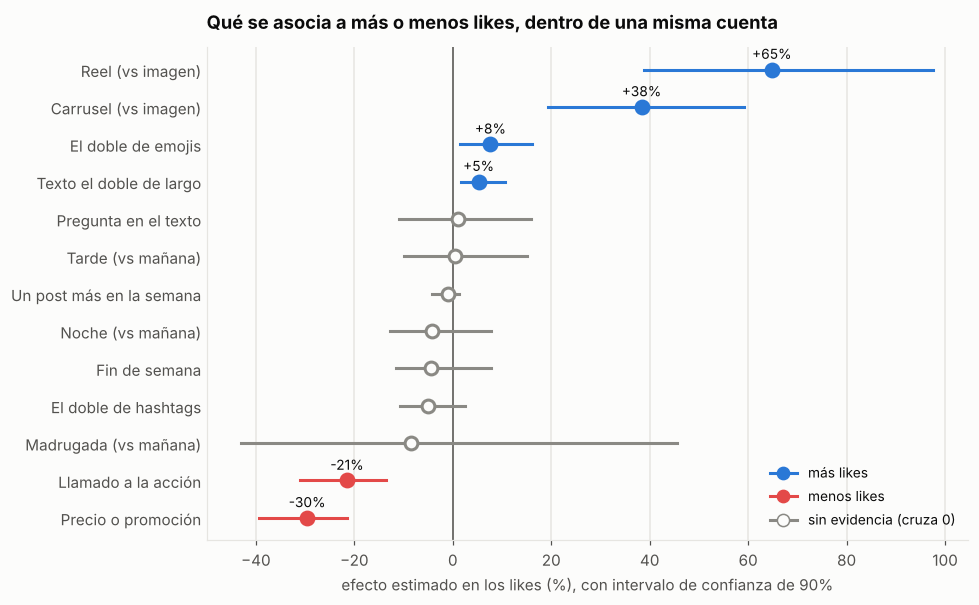

In [3]:
decisiones = tabla[tabla["accionable"]].sort_values("efecto_%").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 5.6))
ax.axvline(0, color=TINTA_2, linewidth=1, zorder=1)
for y, f in decisiones.iterrows():
    color = COLOR_CONCLUSION[f["conclusion"]]
    claro = f["conclusion"] != "sin evidencia suficiente"
    ax.plot([f["efecto_bajo_%"], f["efecto_alto_%"]], [y, y], color=color, linewidth=2, zorder=2)
    ax.scatter(f["efecto_%"], y, s=70, zorder=3, color=color if claro else FONDO, edgecolor=color, linewidth=2)
    if claro:
        ax.annotate(f"{f['efecto_%']:+.0f}%", (f["efecto_%"], y), xytext=(0, 7), textcoords="offset points",
                    ha="center", fontsize=9, color=TINTA)
ax.set_yticks(range(len(decisiones)), decisiones["nombre"])
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("efecto estimado en los likes (%), con intervalo de confianza de 90%")
ax.set_title("Qué se asocia a más o menos likes, dentro de una misma cuenta")
ax.legend(handles=[
    Line2D([], [], marker="o", color=AZUL, markerfacecolor=AZUL, markersize=8, linewidth=2, label="más likes"),
    Line2D([], [], marker="o", color=ROJO, markerfacecolor=ROJO, markersize=8, linewidth=2, label="menos likes"),
    Line2D([], [], marker="o", color=GRIS, markerfacecolor=FONDO, markersize=8, linewidth=2, label="sin evidencia (cruza 0)"),
], loc="lower right", fontsize=9)
plt.tight_layout()
guardar(fig, "efectos")
plt.show()

In [4]:
controles = tabla.set_index("variable").loc[["nivel_reciente", "log_seguidores"]]
for v, f in controles.iterrows():
    print(f"{im.NOMBRES[v]}: {f['efecto_%']:+.1f}%  [IC 90%: {f['efecto_bajo_%']:+.1f}% a {f['efecto_alto_%']:+.1f}%]")

Cuenta un 10% más arriba últimamente: +8.4%  [IC 90%: +6.6% a +8.8%]
El doble de seguidores: +10.3%  [IC 90%: +6.3% a +18.8%]


**Lectura:**

- **Formato.** Un reel rinde cerca de **+65%** más que una imagen sola de la misma cuenta, y un carrusel cerca de **+38%**.
  Son los efectos más grandes y los más estables (el signo se mantiene en más del 99% de las repeticiones).
- **Posts promocionales.** Con **llamado a la acción** (agenda, reserva, WhatsApp) rinden cerca de **−21%**, y los que
  mencionan **precios o promociones**, cerca de **−30%**. Es esperable: son avisos, no contenido. No significa que haya
  que dejar de publicarlos, sino que su éxito se mide en reservas y no en likes.
- **Texto.** Un texto propio el doble de largo se asocia a **+5%** y el doble de emojis a **+8%**. Son efectos chicos y con
  intervalos que casi tocan el 0: sugerentes, no concluyentes.
- **Sin evidencia:** la hora del día, el fin de semana, las preguntas, los hashtags y la frecuencia de publicación. Sus
  intervalos cruzan el 0 y su signo cambia en buena parte de las repeticiones.
- **Controles.** El nivel reciente de la cuenta es, por lejos, lo que más pesa: si una cuenta viene rindiendo un 10% más,
  se espera cerca de un 8% más en el próximo post. Y el doble de seguidores se asocia a apenas un 10% más de likes **a igual
  nivel reciente**, porque el nivel ya refleja casi todo lo que aporta el tamaño.

## 2. ¿Coincide con la Fase 3?

En la Fase 3 se compararon grupos de posts **dentro de cada cuenta**, sin modelo: por ejemplo, el promedio de log_likes
de los carruseles menos el de las imágenes, cuenta por cuenta. El modelo hace algo parecido, pero controlando todas las
variables a la vez. Si las dos miradas apuntan a lo mismo, la conclusión es más sólida.

In [5]:
simples = im.efectos_dentro_de_cuentas(df).set_index("comparacion")
pares = {
    "Reel vs no reel": "es_reel", "Carrusel vs imagen": "es_carrusel",
    "Con llamado a la acción vs sin": "tiene_llamado_accion", "Con pregunta vs sin": "tiene_pregunta",
    "Fin de semana vs lunes a viernes": "es_fin_de_semana", "Tarde vs mañana": "franja_tarde",
}
modelo = tabla.set_index("variable")
rango = lambda c, b, a: f"{c:+.0f}% [{b:+.0f}, {a:+.0f}]"
comparacion = pd.DataFrame([{
    "comparación": comp,
    "cuentas (Fase 3)": int(simples.loc[comp, "cuentas"]),
    "Fase 3: dentro de cada cuenta": rango(simples.loc[comp, "media_%"], simples.loc[comp, "ic_bajo_%"], simples.loc[comp, "ic_alto_%"]),
    "señal Fase 3": simples.loc[comp, "señal"],
    "Fase 5: modelo": rango(modelo.loc[v, "efecto_%"], modelo.loc[v, "efecto_bajo_%"], modelo.loc[v, "efecto_alto_%"]),
    "conclusión del modelo": modelo.loc[v, "conclusion"],
} for comp, v in pares.items()]).set_index("comparación")
comparacion

,cuentas (Fase 3),Fase 3: dentro de cada cuenta,señal Fase 3,Fase 5: modelo,conclusión del modelo
comparación,,,,,
Reel vs no reel,13,"+18% [-11, +51]",no concluyente,"+65% [+39, +98]",aumenta los likes
Carrusel vs imagen,7,"+62% [+28, +106]",clara,"+38% [+19, +59]",aumenta los likes
Con llamado a la acción vs sin,16,"-23% [-35, -9]",clara,"-21% [-31, -14]",reduce los likes
Con pregunta vs sin,13,"-1% [-13, +13]",no concluyente,"+1% [-11, +16]",sin evidencia suficiente
Fin de semana vs lunes a viernes,14,"+9% [-6, +26]",no concluyente,"-4% [-11, +8]",sin evidencia suficiente
Tarde vs mañana,16,"+11% [-4, +29]",no concluyente,"+0% [-10, +15]",sin evidencia suficiente


In [6]:
# El modelo compara reel y carrusel contra la imagen. ¿Y reel contra carrusel?
reel_vs_carrusel = (np.exp(boot["es_reel"] - boot["es_carrusel"]) - 1) * 100
centro = (np.exp(modelo.loc["es_reel", "coef_original"] - modelo.loc["es_carrusel", "coef_original"]) - 1) * 100
bajo, alto = np.percentile(reel_vs_carrusel, [5, 95])
print(f"Reel vs carrusel: {centro:+.0f}%  [IC 90%: {bajo:+.0f}% a {alto:+.0f}%]")
print(f"Imágenes: {(df['formato'] == 'imagen').mean():.0%} de los posts | carruseles: {(df['formato'] == 'carrusel').mean():.0%}"
      f" | reels: {(df['formato'] == 'reel').mean():.0%}")

Reel vs carrusel: +19%  [IC 90%: -3% a +45%]
Imágenes: 12% de los posts | carruseles: 18% | reels: 70%


Las dos miradas **coinciden** en lo principal: los carruseles rinden más que las imágenes, los posts con llamado a la
acción rinden menos, y ni las preguntas, ni el fin de semana, ni la tarde muestran un efecto claro.

La diferencia está en los **reels**. La Fase 3 comparaba "reel vs todo lo demás", y "todo lo demás" incluye los
carruseles, que también rinden bien; el resultado no fue concluyente. El modelo compara reel contra **imagen** y sí
encuentra un efecto claro. Contra el carrusel, en cambio, la ventaja del reel es menor (cerca de +19%) y su intervalo cruza el 0. La
conclusión honesta: **lo que rinde menos es la imagen sola**; entre reel y carrusel no hay un ganador claro. Además, las
imágenes son solo el 12% de los posts, así que la comparación descansa en pocos datos.

## 3. ¿Depende de una sola barbería?

Con 19 cuentas, una sola cuenta grande podría estar empujando un resultado. Para comprobarlo se reentrena el modelo 19
veces, cada vez **sin una de las cuentas**, y se mira cuánto se mueve cada efecto.

In [7]:
filas = {}
for usuario in df["username"].unique():
    sin_ella = df[df["username"] != usuario].reset_index(drop=True)
    modelo_sin, columnas, _ = em.entrenar_final(sin_ella, NOMBRE_MODELO)
    filas[etiqueta(usuario)] = em.coeficientes(modelo_sin, columnas).set_index("variable")["efecto_%"]
sin_una = pd.DataFrame(filas).T

claras = decisiones.loc[decisiones["conclusion"] != "sin evidencia suficiente", "variable"].tolist()[::-1]
resumen = pd.DataFrame({
    "modelo completo": modelo.loc[claras, "efecto_%"],
    "mínimo sin una cuenta": sin_una[claras].min(),
    "máximo sin una cuenta": sin_una[claras].max(),
    "cuenta que más lo mueve": [(sin_una[v] - modelo.loc[v, "efecto_%"]).abs().idxmax() for v in claras],
    "mismo signo siempre": [bool((np.sign(sin_una[v]) == np.sign(modelo.loc[v, "efecto_%"])).all()) for v in claras],
}, index=claras).rename(index=im.NOMBRES)
resumen.round(1)

,modelo completo,mínimo sin una cuenta,máximo sin una cuenta,cuenta que más lo mueve,mismo signo siempre
Reel (vs imagen),64.8,59.5,76.0,Barbería 09,True
Carrusel (vs imagen),38.3,30.7,49.1,Barbería 04,True
El doble de emojis,7.7,4.8,9.8,Barbería 03,True
Texto el doble de largo,5.2,3.7,7.1,Barbería 03,True
Llamado a la acción,-21.5,-25.4,-19.2,Barbería 01,True
Precio o promoción,-29.6,-32.4,-27.3,Barbería 02,True


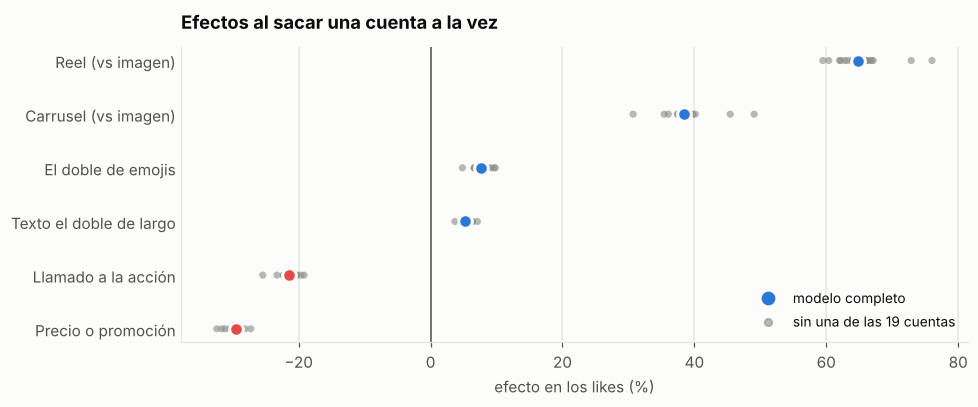

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axvline(0, color=TINTA_2, linewidth=1, zorder=1)
for y, v in enumerate(claras[::-1]):           # el efecto más grande arriba
    color = COLOR_CONCLUSION[modelo.loc[v, "conclusion"]]
    ax.scatter(sin_una[v], np.full(len(sin_una), y), s=22, color=GRIS, alpha=0.6, edgecolor="none", zorder=2)
    ax.scatter(modelo.loc[v, "efecto_%"], y, s=80, color=color, edgecolor=FONDO, linewidth=2, zorder=3)
ax.set_yticks(range(len(claras)), [im.NOMBRES[v] for v in claras[::-1]])
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("efecto en los likes (%)")
ax.set_title("Efectos al sacar una cuenta a la vez")
ax.legend(handles=[
    Line2D([], [], marker="o", linestyle="", color=AZUL, markersize=8, label="modelo completo"),
    Line2D([], [], marker="o", linestyle="", color=GRIS, alpha=0.6, markersize=5, label="sin una de las 19 cuentas"),
], loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

Ningún efecto cambia de signo al sacar una cuenta, así que ninguna conclusión depende de una sola barbería. Algunos se
mueven bastante (sobre todo los de formato, que dependen de cuántas imágenes publica cada cuenta), pero se mantienen del
mismo lado del 0.

## 4. Recomendaciones

Solo se recomienda lo que cumple tres condiciones: la barbería lo decide al publicar, el intervalo de confianza no cruza
el 0 y el efecto no cambia de signo al sacar una cuenta.

In [9]:
recomendaciones = decisiones[decisiones["conclusion"] != "sin evidencia suficiente"].copy()
recomendaciones["efecto"] = recomendaciones.apply(
    lambda f: f"{f['efecto_%']:+.0f}% (entre {f['efecto_bajo_%']:+.0f}% y {f['efecto_alto_%']:+.0f}%)", axis=1)
(recomendaciones.sort_values("efecto_%", key=abs, ascending=False)
 [["nombre", "efecto", "recomendacion"]].set_index("nombre"))

,efecto,recomendacion
nombre,,
Reel (vs imagen),+65% (entre +39% y +98%),Priorizar reels por sobre imágenes sueltas.
Carrusel (vs imagen),+38% (entre +19% y +59%),"Si no es reel, preferir un carrusel antes que una imagen sola."
Precio o promoción,-30% (entre -39% y -21%),"Los posts con precios o promociones reciben menos likes. Igual que el llamado a la acción: su objetivo es vender, no sumar likes. Ojo: hay pocos posts de este tipo."
Llamado a la acción,-21% (entre -31% y -14%),"Los posts promocionales (agenda, reserva, WhatsApp) reciben menos likes. No dejar de publicarlos, pero medir su éxito por reservas y no por likes, y alternarlos con contenido."
El doble de emojis,+8% (entre +2% y +16%),Usar emojis en el texto.
Texto el doble de largo,+5% (entre +2% y +11%),Escribir un texto propio más desarrollado (además de la firma fija de la cuenta).


In [10]:
sin_evidencia = decisiones[decisiones["conclusion"] == "sin evidencia suficiente"]
print("Sin evidencia para recomendar nada (el intervalo cruza el 0):")
for _, f in sin_evidencia.sort_values("efecto_%").iterrows():
    print(f"  · {f['nombre']}: {f['efecto_%']:+.0f}% (entre {f['efecto_bajo_%']:+.0f}% y {f['efecto_alto_%']:+.0f}%)")

Sin evidencia para recomendar nada (el intervalo cruza el 0):
  · Madrugada (vs mañana): -8% (entre -43% y +46%)
  · El doble de hashtags: -5% (entre -11% y +2%)
  · Fin de semana: -4% (entre -11% y +8%)
  · Noche (vs mañana): -4% (entre -13% y +8%)
  · Un post más en la semana: -1% (entre -4% y +1%)
  · Tarde (vs mañana): +0% (entre -10% y +15%)
  · Pregunta en el texto: +1% (entre -11% y +16%)


En la práctica, para una barbería de Santiago:

1. **Publicar en reel o carrusel, no en imagen sola.** Es el cambio más grande y el más seguro.
2. **Separar el contenido de los avisos.** Los posts con llamado a reservar o con precios reciben menos likes; tiene
   sentido publicarlos, pero intercalados con contenido (cortes, procesos, el equipo) y midiendo su éxito por las reservas.
3. **Escribir un texto propio con algo de desarrollo y emojis** suma un poco, pero el efecto es chico: no es lo prioritario.
4. **No obsesionarse con la hora, el día, los hashtags ni las preguntas.** Con estos datos, ninguno muestra un efecto
   claro. Los consejos genéricos de "publica a las 19:00" no se sostienen aquí.

## 5. Cuánto cambia un post concreto

Para hacer tangibles los efectos, se comparan cinco versiones de un post de la **misma cuenta y el mismo día**. La base es
una imagen sin promoción, con un texto propio de 80 caracteres y sin emojis. Lo que se muestra es cuántas veces los
likes de esa base predice el modelo para cada versión, con el intervalo del bootstrap.

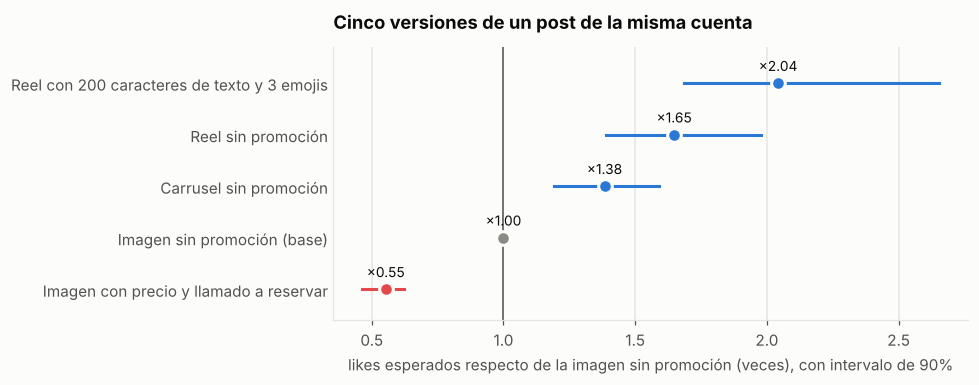

Si una imagen sin promoción de una cuenta suele sacar 30 likes:
  Imagen con precio y llamado a reservar: ~17 likes (entre 14 y 19)
  Imagen sin promoción (base): ~30 likes
  Carrusel sin promoción: ~42 likes (entre 36 y 48)
  Reel sin promoción: ~49 likes (entre 42 y 59)
  Reel con 200 caracteres de texto y 3 emojis: ~61 likes (entre 51 y 80)


In [11]:
def version(formato="imagen", llamado=0, precio=0, largo=80, emojis=0):
    return pd.Series({"es_reel": float(formato == "reel"), "es_carrusel": float(formato == "carrusel"),
                      "tiene_llamado_accion": float(llamado), "menciona_precio_promo": float(precio),
                      "log_largo_texto": np.log1p(largo), "log_emojis": np.log1p(emojis)})


versiones = {
    "Imagen con precio y llamado a reservar": version(llamado=1, precio=1),
    "Imagen sin promoción (base)": version(),
    "Carrusel sin promoción": version("carrusel"),
    "Reel sin promoción": version("reel"),
    "Reel con 200 caracteres de texto y 3 emojis": version("reel", largo=200, emojis=3),
}
base = versiones["Imagen sin promoción (base)"]
coef = modelo["coef_original"]
filas = []
for nombre, v in versiones.items():
    delta = v - base
    veces_boot = np.exp(boot[delta.index].to_numpy() @ delta.to_numpy())
    filas.append({"versión": nombre, "veces": float(np.exp((coef[delta.index] * delta).sum())),
                  "bajo": np.percentile(veces_boot, 5), "alto": np.percentile(veces_boot, 95)})
escenarios = pd.DataFrame(filas).set_index("versión")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axvline(1, color=TINTA_2, linewidth=1, zorder=1)
for y, (nombre, f) in enumerate(escenarios.iterrows()):
    es_base = "(base)" in nombre
    color = GRIS if es_base else (AZUL if f["veces"] > 1 else ROJO)
    if not es_base:
        ax.plot([f["bajo"], f["alto"]], [y, y], color=color, linewidth=2, zorder=2)
    ax.scatter(f["veces"], y, s=80, color=color, edgecolor=FONDO, linewidth=2, zorder=3)
    ax.annotate(f"×{f['veces']:.2f}", (f["veces"], y), xytext=(0, 8), textcoords="offset points", ha="center",
                fontsize=9, color=TINTA)
ax.set_yticks(range(len(escenarios)), escenarios.index)
ax.set_ylim(-0.6, len(escenarios) - 0.3)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("likes esperados respecto de la imagen sin promoción (veces), con intervalo de 90%")
ax.set_title("Cinco versiones de un post de la misma cuenta")
plt.tight_layout()
guardar(fig, "versiones_post")
plt.show()

likes_base = 30
print(f"Si una imagen sin promoción de una cuenta suele sacar {likes_base} likes:")
for nombre, f in escenarios.iterrows():
    rango = "" if "(base)" in nombre else f" (entre {likes_base * f['bajo']:.0f} y {likes_base * f['alto']:.0f})"
    print(f"  {nombre}: ~{likes_base * f['veces']:.0f} likes{rango}")

Pasar de un aviso en imagen a un reel de contenido con algo de texto y emojis multiplica los likes esperados por más
de 3 (de ×0,55 a ×2,04 respecto de la base).
Pero recuerda la Fase 4: cada post individual varía mucho (error típico ×2), así que esto describe el promedio de muchos
posts, no lo que va a pasar con el próximo.

## 6. Limitaciones

- **Son asociaciones, no experimentos.** Si los reels rinden más, puede ser por el formato o porque las barberías usan
  reels para su mejor contenido. Solo un experimento (publicar lo mismo en dos formatos al azar) separaría ambas cosas.
  Tampoco se observa si un post fue promocionado con publicidad pagada o si fue una colaboración.
- **Los likes no son el objetivo del negocio.** Los posts con llamado a la acción buscan reservas, que no se ven en los
  datos públicos. Business Discovery tampoco entrega alcance, guardados ni compartidos de cuentas de terceros.
- **Muestra chica y de un solo nicho.** 19 barberías de Santiago y 12 meses. Algunos grupos son muy chicos: 31 posts con
  precio o promoción (en 7 cuentas), 26 de madrugada y 159 imágenes. Los resultados no se pueden extender sin más a otros
  rubros o ciudades.
- **Las variables de texto son reglas simples.** El llamado a la acción, las preguntas y las promociones se detectan con
  expresiones regulares (Fase 2); habrá algunos falsos positivos y negativos.
- **Comparaciones múltiples.** Se miran 13 variables con intervalos de 90%. Aunque ninguna influyera, se esperaría que
  1 o 2 aparecieran como "claras" por azar. Los efectos de formato y de promoción tienen un signo estable en más del
  99% de las repeticiones, así que es muy improbable que sean azar. Los de texto y emojis (97% a 99%) son más frágiles.
- **Los virales no se explican.** Los grandes picos son humor y contingencia, algo que ninguna variable captura.

## 7. Conclusiones

*Números de la corrida del 15-10-2026 (19 cuentas, 1.292 posts). Si vuelves a extraer, cambian un poco; las celdas de
arriba siempre muestran los valores actuales.*

1. **Lo que más pesa es la propia cuenta**: su tamaño y, sobre todo, su rendimiento reciente. Sobre eso, las decisiones
   del post mueven los likes, pero bastante menos.
2. **El formato es la decisión que más importa**: reels (+65%) y carruseles (+38%) rinden más que una imagen sola de la
   misma cuenta. Entre reel y carrusel no hay un ganador claro.
3. **Los avisos reciben menos likes**: llamado a la acción (−21%) y precios o promociones (−30%). Hay que medirlos por
   reservas, no por likes.
4. **El texto suma poco** (más largo +5%, emojis +8%), y **la hora, el día, los hashtags, las preguntas y la frecuencia
   no muestran efecto**.
5. **Ninguna conclusión depende de una sola barbería**, y las dos miradas (comparaciones simples de la Fase 3 y el modelo)
   coinciden en lo principal.

**Siguientes pasos** (fases 6 y 7): predecir el rendimiento de un post a las pocas horas de publicado, con capturas
repetidas de sus likes, y agrupar a las barberías según su estrategia de contenido.